# Huấn luyện ResNet-18 From Scratch (30 Epochs) — Kiểu A — Multi-class Softmax (9 nhóm tuổi)
Notebook huấn luyện **từ đầu (from scratch, Kaiming He Initialization)** trên tập dữ liệu khuôn mặt Châu Á (`16.522` ảnh, `224×224`, cân bằng `WeightedRandomSampler` + Augmentation `RandomAffine` & `RandomErasing / Coarse Dropout` theo Mục `2.3.5` báo cáo PDF):

- **Nhánh Giới tính (`gender_head`):** `Linear(512, 1)` $\rightarrow$ `Sigmoid` trả về **1 xác suất trong khoảng $(0, 1)$** (`0 = Female`, `1 = Male`), tối ưu bằng `BCEWithLogitsLoss` + **Label Smoothing ($\alpha = 0.1$)**.
- **Nhánh Tuổi (`age_head`):** `Linear(512, 9)` + **CrossEntropyLoss** (phân loại đa lớp 9 nhóm tuổi qua Softmax — giống ResNet50 trong Báo cáo PDF), chỉ dự đoán **1 trong 9 nhóm tuổi** (`0-2`, `3-9`, `10-19`, `20-29`, `30-39`, `40-49`, `50-59`, `60-69`, `70+`).
- **Tự động xuất đầy đủ 5 biểu đồ báo cáo & lưu riêng vào `results/resnet18_typeA/` và `checkpoints/resnet18_typeA_best.pth`** để đối chiếu trực tiếp giữa Kiểu A và Kiểu B.

In [1]:
# [Cell 1] Thiết lập môi trường (Colab hỗ trợ dataset.zip / Local), GPU & Seed
import os, sys, random, json, time, shutil
import numpy as np
import torch

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

AGE_MODE = "multiclass"   # 'multiclass' (Kiểu A) hoặc 'coral' (Kiểu B)
EXP_TAG = "resnet18_typeA"
IN_COLAB = "google.colab" in sys.modules
DRIVE_SAVE_DIR = None
IMG_ROOT_OVERRIDE = None

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    DRIVE_DATASET_ZIP = "/content/drive/MyDrive/dataset.zip"
    DRIVE_PROJECT_DIR = "/content/drive/MyDrive/FINAL-PROJECT"
    DRIVE_SAVE_DIR = f"/content/drive/MyDrive/{EXP_TAG}_outputs"
    os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)

    if os.path.exists(DRIVE_DATASET_ZIP):
        if not os.path.exists("/content/dataset/metadata/train.csv"):
            print(f"Đang giải nén {DRIVE_DATASET_ZIP} sang /content/ ...")
            !unzip -q "{DRIVE_DATASET_ZIP}" -d "/content"
        if os.path.exists("/content/dataset/dataset/metadata/train.csv"):
            os.chdir("/content/dataset")
        elif os.path.exists("/content/dataset/metadata/train.csv"):
            os.chdir("/content")
        else:
            raise FileNotFoundError("Không tìm thấy dataset/metadata/train.csv sau khi giải nén dataset.zip!")
    elif os.path.exists(DRIVE_PROJECT_DIR):
        os.chdir(DRIVE_PROJECT_DIR)
    else:
        raise FileNotFoundError("Không tìm thấy /content/drive/MyDrive/dataset.zip!")
else:
    cur = os.path.abspath(os.getcwd())
    while not os.path.isdir(os.path.join(cur, "dataset", "metadata")) and cur != os.path.dirname(cur):
        cur = os.path.dirname(cur)
    os.chdir(cur)

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Experiment: {EXP_TAG} (AGE_MODE={AGE_MODE}) | Working dir: {os.getcwd()}")
print("Device:", device, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Mounted at /content/drive
Đang giải nén /content/drive/MyDrive/dataset.zip sang /content/ ...
Experiment: resnet18_typeA (AGE_MODE=multiclass) | Working dir: /content
Device: cuda | GPU: Tesla T4


In [2]:
# [Cell 2] Đọc dữ liệu 9 nhóm tuổi (age_group 0..8) & Giới tính (0.0/1.0), Data Augmentation (Mục 2.3.5 PDF) & DataLoader
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms

AGE_GROUPS_9 = ["0-2", "3-9", "10-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70+"]
AGE_GROUP_TO_IDX = {g: i for i, g in enumerate(AGE_GROUPS_9)}

with open("dataset/metadata/norm_stats.json", "r", encoding="utf-8") as f:
    norm_stats = json.load(f)
TRAIN_MEAN, TRAIN_STD = norm_stats["mean"], norm_stats["std"]

IMG_SIZE = 224
BATCH_SIZE = 64
NUM_WORKERS = 0  # Đặt 0 để tương thích hoàn toàn với Python 3.13 trên Google Colab
USE_BALANCED_SAMPLER = True

# Tiền xử lý & Tăng cường dữ liệu đồng bộ theo Mục 2.3.5 Báo cáo PDF (Flip + Affine + ColorJitter + RandomErasing/CoarseDropout)
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=15, translate=(0.08, 0.08), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=TRAIN_MEAN, std=TRAIN_STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.12), value=0),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=TRAIN_MEAN, std=TRAIN_STD),
])

class AsianFaceGroupDataset(Dataset):
    def __init__(self, csv_path, transform=None, img_root_override=None):
        self.df = pd.read_csv(csv_path)
        if img_root_override:
            self.df["image_path"] = self.df["image_path"].astype(str).str.replace("dataset/processed", img_root_override, regex=False)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(str(row["image_path"]).replace("\\", "/")).convert("RGB")
        if self.transform:
            img = self.transform(img)
        # Giới tính: float32 (0.0 = Female, 1.0 = Male) cho đầu ra 1 xác suất Sigmoid
        gender = torch.tensor(float(row["gender"]), dtype=torch.float32)
        # Nhóm tuổi: int64 (0..8 tương ứng 9 nhóm tuổi '0-2' .. '70+')
        age_grp = torch.tensor(AGE_GROUP_TO_IDX[str(row["age_group"]).strip()], dtype=torch.long)
        return img, gender, age_grp

train_ds = AsianFaceGroupDataset("dataset/metadata/train.csv", transform=train_transform, img_root_override=IMG_ROOT_OVERRIDE)
val_ds = AsianFaceGroupDataset("dataset/metadata/val.csv", transform=val_transform, img_root_override=IMG_ROOT_OVERRIDE)
test_ds = AsianFaceGroupDataset("dataset/metadata/test.csv", transform=val_transform, img_root_override=IMG_ROOT_OVERRIDE)

if USE_BALANCED_SAMPLER:
    strat_key = train_ds.df["age_group"].astype(str) + "_" + train_ds.df["gender"].astype(str)
    counts = strat_key.value_counts().to_dict()
    sample_weights = strat_key.map(lambda k: 1.0 / counts[k]).values
    sampler = WeightedRandomSampler(weights=torch.DoubleTensor(sample_weights), num_samples=len(sample_weights), replacement=True)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS, pin_memory=True)
else:
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)

val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f"Dataset loaded -> Train: {len(train_ds):,} | Val: {len(val_ds):,} | Test: {len(test_ds):,}")
print("9 Age Groups:", AGE_GROUP_TO_IDX)

Dataset loaded -> Train: 11,565 | Val: 2,478 | Test: 2,479
9 Age Groups: {'0-2': 0, '3-9': 1, '10-19': 2, '20-29': 3, '30-39': 4, '40-49': 5, '50-59': 6, '60-69': 7, '70+': 8}


In [3]:
# [Cell 3] Kiến trúc ResNet-18 From Scratch + Multi-task Head (Gender: 1 xác suất (0,1) | Age: 9 nhóm tuổi)
import torch.nn as nn
import torch.nn.functional as F

class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels * self.expansion:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels * self.expansion, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels * self.expansion),
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return self.relu(out)


class ResNet18MultiTask(nn.Module):
    def __init__(self, age_mode="coral", num_age_groups=9, dropout=0.3):
        super().__init__()
        assert age_mode in ("multiclass", "coral")
        self.age_mode = age_mode
        self.num_age_groups = num_age_groups
        self.in_channels = 64

        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        self.layer1 = self._make_layer(64, num_blocks=2, stride=1)
        self.layer2 = self._make_layer(128, num_blocks=2, stride=2)
        self.layer3 = self._make_layer(256, num_blocks=2, stride=2)
        self.layer4 = self._make_layer(512, num_blocks=2, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(dropout)

        # Nhánh Giới tính: Linear(512, 1) -> qua Sigmoid trả về 1 xác suất trong khoảng (0, 1)
        self.gender_head = nn.Linear(512 * BasicBlock.expansion, 1)

        # Nhánh Tuổi: Kiểu A ('multiclass') = Linear(512, 9) | Kiểu B ('coral') = Linear(512, 8)
        age_out_dim = (num_age_groups - 1) if age_mode == "coral" else num_age_groups
        self.age_head = nn.Linear(512 * BasicBlock.expansion, age_out_dim)
        self._init_weights()

    def _make_layer(self, out_channels, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for s in strides:
            layers.append(BasicBlock(self.in_channels, out_channels, stride=s))
            self.in_channels = out_channels * BasicBlock.expansion
        return nn.Sequential(*layers)

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def extract_features(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return self.avgpool(x).flatten(1)  # (B, 512)

    def forward(self, x):
        feats = self.dropout(self.extract_features(x))
        gender_logit = self.gender_head(feats).squeeze(1)  # (B,)
        age_logits = self.age_head(feats)                  # (B, 9) hoặc (B, 8)
        return gender_logit, age_logits

    @torch.no_grad()
    def predict_proba(self, x):
        g_logit, a_logits = self.forward(x)
        g_prob_male = torch.sigmoid(g_logit)  # 1 xác suất trong khoảng (0, 1)
        if self.age_mode == "coral":
            a_scores = torch.sigmoid(a_logits)
            a_pred_grp = (a_scores > 0.5).sum(dim=1).long()
        else:
            a_scores = torch.softmax(a_logits, dim=1)
            a_pred_grp = a_scores.argmax(dim=1).long()
        return g_prob_male, a_pred_grp, a_scores

model = ResNet18MultiTask(age_mode=AGE_MODE, num_age_groups=9, dropout=0.3).to(device)
print(f"ResNet-18 Multi-task ({AGE_MODE.upper()}) | Gender output: 1 prob in (0,1) | Age head output dim: {model.age_head.out_features} | Params: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")

ResNet-18 Multi-task (MULTICLASS) | Gender output: 1 prob in (0,1) | Age head output dim: 9 | Params: 11.18M


In [4]:
# [Cell 4] Thiết kế Hàm mất mát (BCEWithLogits + Label Smoothing 0.1 cho Giới tính | CrossEntropy / CORAL cho 9 Nhóm tuổi)
NUM_EPOCHS = 30
LR = 1e-3
W_GENDER = 1.0
W_AGE = 3.0            # Trọng số ưu tiên nhánh Tuổi theo Mục 2.5.1b Báo cáo PDF (Loss_total = 1*L_gender + 3*L_age)
LABEL_SMOOTHING = 0.1  # Làm mượt nhãn giới tính (0 -> 0.05, 1 -> 0.95) chống Overconfidence
EARLY_STOP_PATIENCE = 10

bce_gender = nn.BCEWithLogitsLoss()
ce_age = nn.CrossEntropyLoss()

def compute_gender_loss(g_logit, g_true):
    g_target = g_true.float() * (1.0 - LABEL_SMOOTHING) + 0.5 * LABEL_SMOOTHING
    return bce_gender(g_logit, g_target)

def compute_age_loss(a_logits, a_true_grp):
    if AGE_MODE == "coral":
        # Phân rã K=9 nhóm tuổi thành K-1=8 tác vụ nhị phân nối tiếp P(y > k)
        thresholds = torch.arange(8, device=a_logits.device).unsqueeze(0)
        levels = (a_true_grp.unsqueeze(1) > thresholds).float()
        return F.binary_cross_entropy_with_logits(a_logits, levels)
    return ce_age(a_logits, a_true_grp.long())

def decode_age_group(a_logits):
    if AGE_MODE == "coral":
        return (torch.sigmoid(a_logits) > 0.5).sum(dim=1).long()
    return a_logits.argmax(dim=1).long()

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

In [5]:
# [Cell 5] Vòng lặp Huấn luyện 30 Epochs (Log Loss & Accuracy riêng của Gender và 9 Nhóm tuổi + Early Stopping)
from tqdm.auto import tqdm

CKPT_DIR = "checkpoints"
OUT_DIR = f"results/{EXP_TAG}"
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
BEST_CKPT_PATH = os.path.join(CKPT_DIR, f"{EXP_TAG}_best.pth")

history = []
best_val_loss = float("inf")
best_val_age_acc = 0.0
epochs_no_improve = 0
t_start = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    # --- TRAIN ---
    model.train()
    tr_loss, tr_g_loss, tr_a_loss = 0.0, 0.0, 0.0
    tr_g_ok, tr_a_ok, tr_a_adj_ok, tr_n = 0, 0, 0, 0

    for imgs, genders, age_grps in tqdm(train_loader, desc=f"Epoch {epoch:02d}/{NUM_EPOCHS} [Train]", leave=False):
        imgs = imgs.to(device, non_blocking=True)
        genders = genders.to(device, non_blocking=True)
        age_grps = age_grps.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            g_logit, a_logits = model(imgs)
            lg = compute_gender_loss(g_logit, genders)
            la = compute_age_loss(a_logits, age_grps)
            loss = W_GENDER * lg + W_AGE * la

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        bs = imgs.size(0)
        tr_loss += loss.item() * bs
        tr_g_loss += lg.item() * bs
        tr_a_loss += la.item() * bs

        g_pred = (torch.sigmoid(g_logit) >= 0.5).long()
        a_pred = decode_age_group(a_logits)
        tr_g_ok += (g_pred == genders.long()).sum().item()
        tr_a_ok += (a_pred == age_grps).sum().item()
        tr_a_adj_ok += (torch.abs(a_pred - age_grps) <= 1).sum().item()
        tr_n += bs

    # --- VALIDATION ---
    model.eval()
    va_loss, va_g_loss, va_a_loss = 0.0, 0.0, 0.0
    va_g_ok, va_a_ok, va_a_adj_ok, va_n = 0, 0, 0, 0
    with torch.no_grad():
        for imgs, genders, age_grps in val_loader:
            imgs = imgs.to(device, non_blocking=True)
            genders = genders.to(device, non_blocking=True)
            age_grps = age_grps.to(device, non_blocking=True)

            g_logit, a_logits = model(imgs)
            lg = compute_gender_loss(g_logit, genders)
            la = compute_age_loss(a_logits, age_grps)
            loss = W_GENDER * lg + W_AGE * la

            bs = imgs.size(0)
            va_loss += loss.item() * bs
            va_g_loss += lg.item() * bs
            va_a_loss += la.item() * bs

            g_pred = (torch.sigmoid(g_logit) >= 0.5).long()
            a_pred = decode_age_group(a_logits)
            va_g_ok += (g_pred == genders.long()).sum().item()
            va_a_ok += (a_pred == age_grps).sum().item()
            va_a_adj_ok += (torch.abs(a_pred - age_grps) <= 1).sum().item()
            va_n += bs

    scheduler.step()

    row = {
        "epoch": epoch,
        "tr_loss": tr_loss / tr_n, "tr_gender_loss": tr_g_loss / tr_n, "tr_age_loss": tr_a_loss / tr_n,
        "tr_acc": tr_g_ok / tr_n, "tr_age_grp_acc": tr_a_ok / tr_n, "tr_age_adj_acc": tr_a_adj_ok / tr_n,
        "val_loss": va_loss / va_n, "val_gender_loss": va_g_loss / va_n, "val_age_loss": va_a_loss / va_n,
        "val_acc": va_g_ok / va_n, "val_age_grp_acc": va_a_ok / va_n, "val_age_adj_acc": va_a_adj_ok / va_n,
    }
    history.append(row)
    print(f"Epoch [{epoch:02d}/{NUM_EPOCHS}] | "
          f"Tr G_Loss: {row['tr_gender_loss']:.3f}, A_Loss: {row['tr_age_loss']:.3f}, G_Acc: {row['tr_acc']*100:.1f}%, A_Acc: {row['tr_age_grp_acc']*100:.1f}% | "
          f"Val G_Loss: {row['val_gender_loss']:.3f}, A_Loss: {row['val_age_loss']:.3f}, G_Acc: {row['val_acc']*100:.1f}%, A_Acc: {row['val_age_grp_acc']*100:.1f}% (Adj±1: {row['val_age_adj_acc']*100:.1f}%)")

    # Lưu checkpoint tốt nhất theo val_loss (hoặc đỉnh val_age_grp_acc)
    if row["val_loss"] < best_val_loss:
        best_val_loss = row["val_loss"]
        best_val_age_acc = row["val_age_grp_acc"]
        epochs_no_improve = 0
        torch.save({
            "epoch": epoch,
            "age_mode": AGE_MODE,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "best_val_age_acc": best_val_age_acc,
        }, BEST_CKPT_PATH)
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= EARLY_STOP_PATIENCE:
            print(f"Early Stopping kích hoạt tại epoch {epoch} (không cải thiện Val Loss sau {EARLY_STOP_PATIENCE} epochs).")
            break

torch.save({
    "epoch": len(history),
    "age_mode": AGE_MODE,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "best_val_loss": best_val_loss,
}, os.path.join(CKPT_DIR, f"{EXP_TAG}_last.pth"))

pd.DataFrame(history).to_csv(os.path.join(OUT_DIR, "history.csv"), index=False)
if DRIVE_SAVE_DIR:
    shutil.copytree(CKPT_DIR, os.path.join(DRIVE_SAVE_DIR, "checkpoints"), dirs_exist_ok=True)
    shutil.copytree("results", os.path.join(DRIVE_SAVE_DIR, "results"), dirs_exist_ok=True)
print(f"Hoàn tất huấn luyện ({len(history)} epochs) trong {(time.time()-t_start)/60:.1f} phút! Best Val Age-Group Acc: {best_val_age_acc*100:.2f}%")

Epoch 01/30 [Train]:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [01/30] | Tr G_Loss: 0.693, A_Loss: 2.127, G_Acc: 56.6%, A_Acc: 20.3% | Val G_Loss: 0.679, A_Loss: 1.899, G_Acc: 60.1%, A_Acc: 27.8% (Adj±1: 62.3%)


Epoch 02/30 [Train]:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [02/30] | Tr G_Loss: 0.670, A_Loss: 1.804, G_Acc: 59.9%, A_Acc: 30.4% | Val G_Loss: 0.605, A_Loss: 1.648, G_Acc: 67.9%, A_Acc: 33.9% (Adj±1: 72.0%)


Epoch 03/30 [Train]:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [03/30] | Tr G_Loss: 0.645, A_Loss: 1.607, G_Acc: 63.7%, A_Acc: 35.8% | Val G_Loss: 0.616, A_Loss: 1.737, G_Acc: 66.3%, A_Acc: 32.5% (Adj±1: 66.3%)


... (50 outputs left out)

Epoch 29/30 [Train]:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [29/30] | Tr G_Loss: 0.430, A_Loss: 0.791, G_Acc: 84.4%, A_Acc: 66.8% | Val G_Loss: 0.418, A_Loss: 1.132, G_Acc: 86.1%, A_Acc: 54.5% (Adj±1: 88.8%)


Epoch 30/30 [Train]:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [30/30] | Tr G_Loss: 0.428, A_Loss: 0.801, G_Acc: 84.8%, A_Acc: 66.4% | Val G_Loss: 0.417, A_Loss: 1.136, G_Acc: 86.1%, A_Acc: 54.4% (Adj±1: 88.9%)
Hoàn tất huấn luyện (30 epochs) trong 45.1 phút! Best Val Age-Group Acc: 54.68%


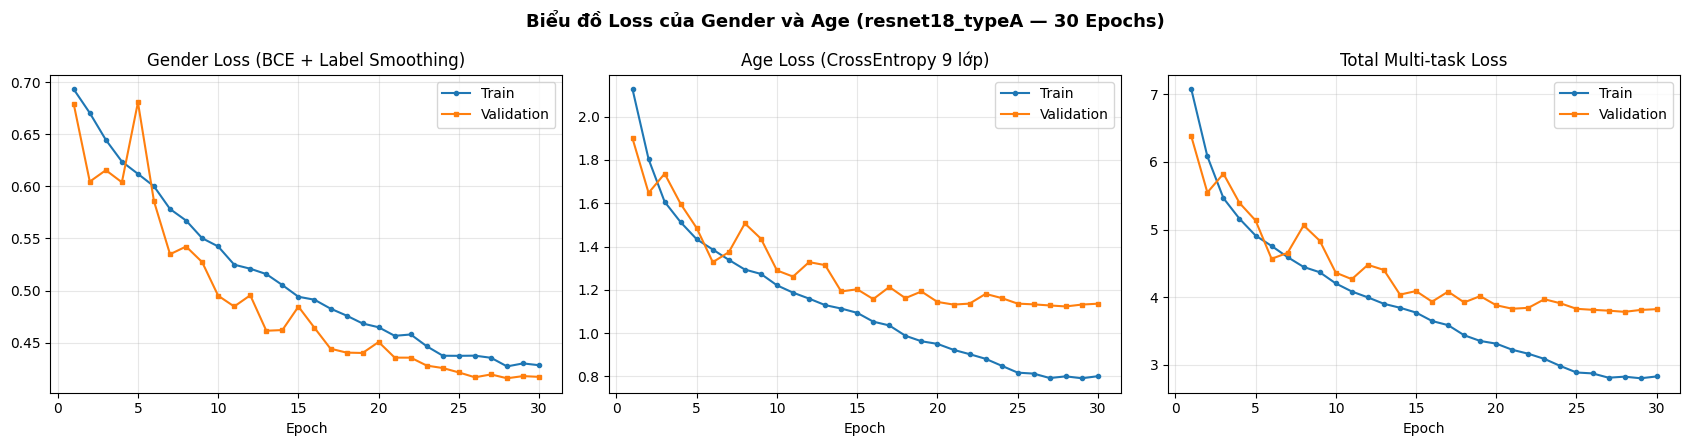

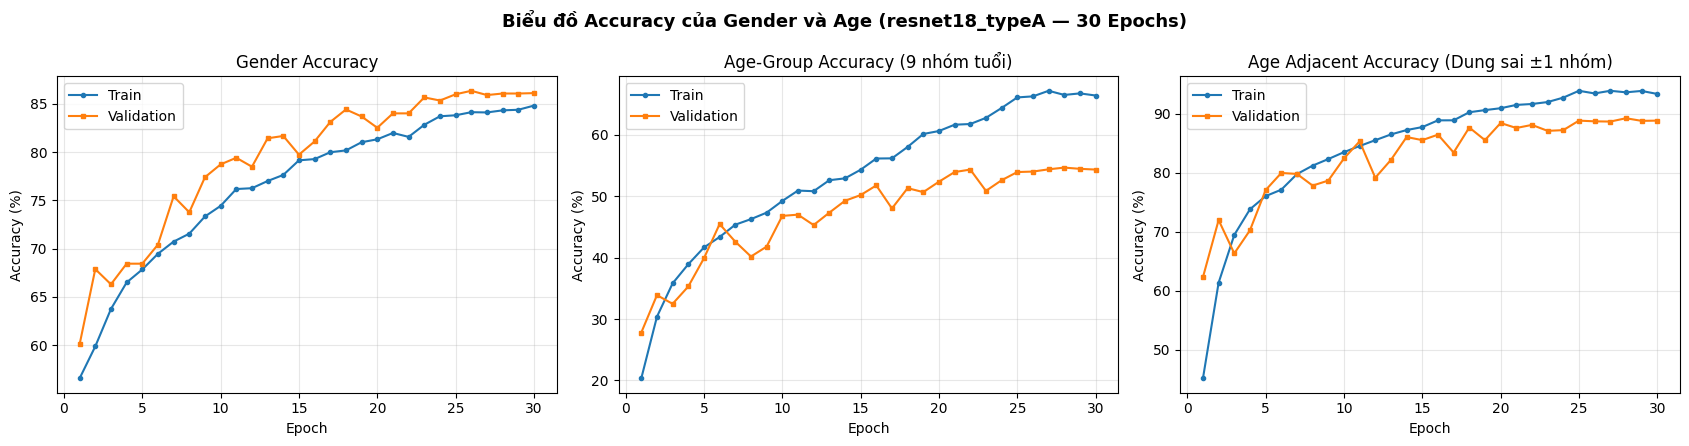

In [6]:
# [Cell 6] Biểu đồ LOSS & ACCURACY của Gender và Age (9 nhóm tuổi) qua các Epochs
import matplotlib.pyplot as plt

hist_df = pd.read_csv(os.path.join(OUT_DIR, "history.csv"))
age_loss_label = "Age Loss (CORAL Ordinal BCE)" if AGE_MODE == "coral" else "Age Loss (CrossEntropy 9 lớp)"

# 1. Biểu đồ Loss của Gender và Age (+ Total Loss)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, cols, title in zip(
    axes,
    [("tr_gender_loss", "val_gender_loss"), ("tr_age_loss", "val_age_loss"), ("tr_loss", "val_loss")],
    ["Gender Loss (BCE + Label Smoothing)", age_loss_label, "Total Multi-task Loss"],
):
    ax.plot(hist_df["epoch"], hist_df[cols[0]], marker="o", markersize=3, label="Train")
    ax.plot(hist_df["epoch"], hist_df[cols[1]], marker="s", markersize=3, label="Validation")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend()
plt.suptitle(f"Biểu đồ Loss của Gender và Age ({EXP_TAG} — {len(hist_df)} Epochs)", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "gender_age_loss_curves.png"), dpi=150); plt.show()

# 2. Biểu đồ Accuracy của Gender và Age (Exact 9 nhóm & Adjacent ±1 nhóm)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, cols, title in zip(
    axes,
    [("tr_acc", "val_acc"), ("tr_age_grp_acc", "val_age_grp_acc"), ("tr_age_adj_acc", "val_age_adj_acc")],
    ["Gender Accuracy", "Age-Group Accuracy (9 nhóm tuổi)", "Age Adjacent Accuracy (Dung sai ±1 nhóm)"],
):
    ax.plot(hist_df["epoch"], hist_df[cols[0]] * 100, marker="o", markersize=3, label="Train")
    ax.plot(hist_df["epoch"], hist_df[cols[1]] * 100, marker="s", markersize=3, label="Validation")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy (%)"); ax.grid(alpha=0.3); ax.legend()
plt.suptitle(f"Biểu đồ Accuracy của Gender và Age ({EXP_TAG} — {len(hist_df)} Epochs)", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "gender_age_accuracy_curves.png"), dpi=150); plt.show()

Loaded Best Checkpoint (Epoch 28) from checkpoints/resnet18_typeA_best.pth


,Tác vụ phân loại,Độ chính xác (Accuracy),Độ chuẩn xác (Precision),Độ thu hồi (Recall),Điểm F1 (F1-score),Chỉ số bổ sung
0,Giới tính (Gender — 1 xác suất Sigmoid),86.65%,86.64%,86.64%,86.64%,ROC-AUC: 94.24%
1,Nhóm tuổi (Age — 9 nhóm [MULTICLASS]),52.60%,53.41%,54.41%,53.62%,Adjacent (±1 nhóm): 89.27%


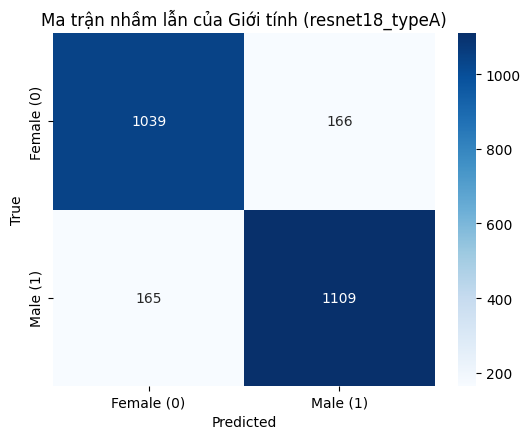

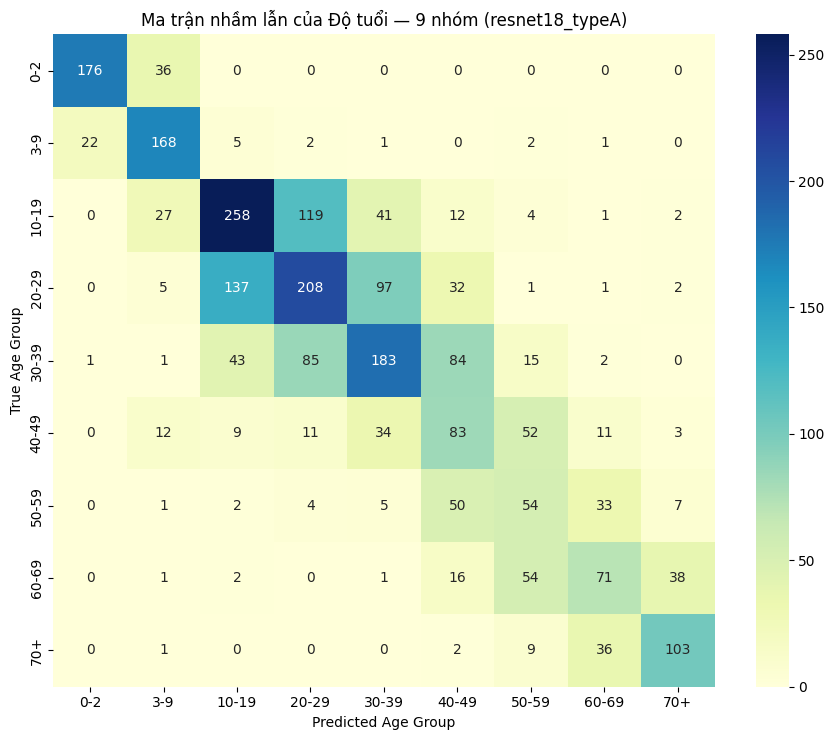

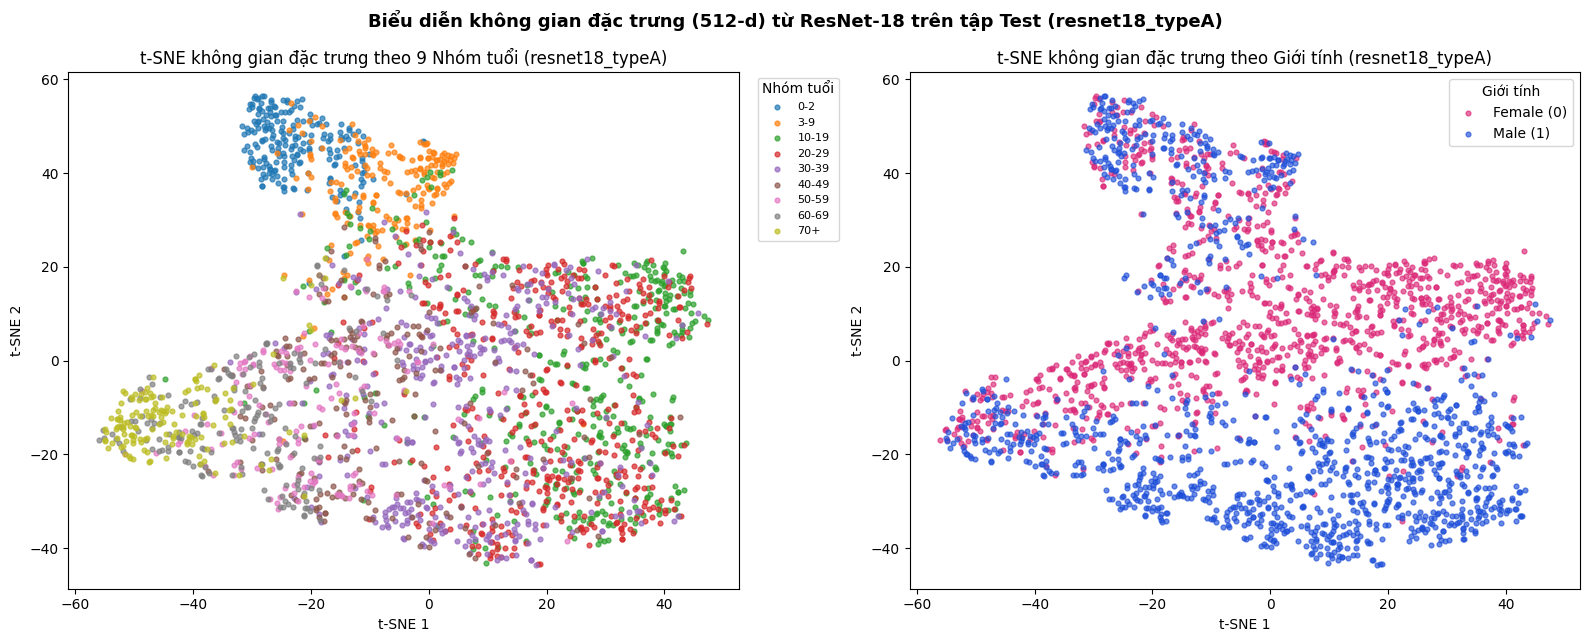

Đã đồng bộ toàn bộ biểu đồ & test_metrics.json lên Google Drive: /content/drive/MyDrive/resnet18_typeA_outputs


In [7]:
# [Cell 7] Đánh giá Tập Test (Bảng 3 PDF: Accuracy, Precision, Recall, F1) + 2 Ma trận nhầm lẫn + t-SNE 512-d
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score

ckpt = torch.load(BEST_CKPT_PATH, map_location=device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()
print(f"Loaded Best Checkpoint (Epoch {ckpt.get('epoch')}) from {BEST_CKPT_PATH}")

all_g_prob, all_g_true, all_a_pred, all_a_true, all_feats = [], [], [], [], []
t0 = time.time()
with torch.no_grad():
    for imgs, genders, age_grps in test_loader:
        imgs_dev = imgs.to(device)
        feats = model.extract_features(imgs_dev)
        g_prob_male, a_pred_grp, _ = model.predict_proba(imgs_dev)
        all_feats.append(feats.cpu().numpy())
        all_g_prob.append(g_prob_male.cpu().numpy())
        all_g_true.append(genders.numpy())
        all_a_pred.append(a_pred_grp.cpu().numpy())
        all_a_true.append(age_grps.numpy())
infer_ms = (time.time() - t0) * 1000.0 / len(test_ds)

feats_np = np.concatenate(all_feats)
gender_prob_male = np.concatenate(all_g_prob)  # 1 xác suất trong khoảng (0, 1)
gender_true = np.concatenate(all_g_true).astype(int)
gender_pred = (gender_prob_male >= 0.5).astype(int)

age_grp_true = np.concatenate(all_a_true).astype(int)
age_grp_pred = np.concatenate(all_a_pred).astype(int)

metrics = {
    "experiment": EXP_TAG,
    "age_mode": AGE_MODE,
    "best_epoch": int(ckpt.get("epoch", 0)),
    "gender_acc": float(accuracy_score(gender_true, gender_pred)),
    "gender_precision": float(precision_score(gender_true, gender_pred, average="macro", zero_division=0)),
    "gender_recall": float(recall_score(gender_true, gender_pred, average="macro", zero_division=0)),
    "gender_f1": float(f1_score(gender_true, gender_pred, average="macro", zero_division=0)),
    "gender_roc_auc": float(roc_auc_score(gender_true, gender_prob_male)),
    "age_group_acc": float(accuracy_score(age_grp_true, age_grp_pred)),
    "age_adjacent_acc (±1 group)": float(np.mean(np.abs(age_grp_pred - age_grp_true) <= 1)),
    "age_precision": float(precision_score(age_grp_true, age_grp_pred, average="macro", zero_division=0)),
    "age_recall": float(recall_score(age_grp_true, age_grp_pred, average="macro", zero_division=0)),
    "age_f1": float(f1_score(age_grp_true, age_grp_pred, average="macro", zero_division=0)),
    "inference_ms_per_img": round(infer_ms, 3),
    "params_M": round(sum(p.numel() for p in model.parameters()) / 1e6, 2),
}
with open(os.path.join(OUT_DIR, "test_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

# Hiển thị Bảng tổng hợp theo đúng chuẩn Bảng 3 trong Báo cáo PDF
summary_table = pd.DataFrame([
    {
        "Tác vụ phân loại": "Giới tính (Gender — 1 xác suất Sigmoid)",
        "Độ chính xác (Accuracy)": f"{metrics['gender_acc']*100:.2f}%",
        "Độ chuẩn xác (Precision)": f"{metrics['gender_precision']*100:.2f}%",
        "Độ thu hồi (Recall)": f"{metrics['gender_recall']*100:.2f}%",
        "Điểm F1 (F1-score)": f"{metrics['gender_f1']*100:.2f}%",
        "Chỉ số bổ sung": f"ROC-AUC: {metrics['gender_roc_auc']*100:.2f}%",
    },
    {
        "Tác vụ phân loại": f"Nhóm tuổi (Age — 9 nhóm [{AGE_MODE.upper()}])",
        "Độ chính xác (Accuracy)": f"{metrics['age_group_acc']*100:.2f}%",
        "Độ chuẩn xác (Precision)": f"{metrics['age_precision']*100:.2f}%",
        "Độ thu hồi (Recall)": f"{metrics['age_recall']*100:.2f}%",
        "Điểm F1 (F1-score)": f"{metrics['age_f1']*100:.2f}%",
        "Chỉ số bổ sung": f"Adjacent (±1 nhóm): {metrics['age_adjacent_acc (±1 group)']*100:.2f}%",
    },
])
display(summary_table)

# 1. Ma trận nhầm lẫn của Giới tính
cm_gender = confusion_matrix(gender_true, gender_pred, labels=[0, 1])
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm_gender, annot=True, fmt="d", cmap="Blues", xticklabels=["Female (0)", "Male (1)"], yticklabels=["Female (0)", "Male (1)"])
plt.title(f"Ma trận nhầm lẫn của Giới tính ({EXP_TAG})"); plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "gender_confusion_matrix.png"), dpi=150); plt.show()

# 2. Ma trận nhầm lẫn của Độ tuổi (9 nhóm tuổi)
cm_age = confusion_matrix(age_grp_true, age_grp_pred, labels=list(range(len(AGE_GROUPS_9))))
plt.figure(figsize=(9, 7.5))
sns.heatmap(cm_age, annot=True, fmt="d", cmap="YlGnBu", xticklabels=AGE_GROUPS_9, yticklabels=AGE_GROUPS_9)
plt.title(f"Ma trận nhầm lẫn của Độ tuổi — 9 nhóm ({EXP_TAG})"); plt.xlabel("Predicted Age Group"); plt.ylabel("True Age Group")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "age_confusion_matrix.png"), dpi=150); plt.show()

# 3. Trực quan hóa không gian đặc trưng 512-d bằng t-SNE (Độ tuổi & Giới tính)
X_pca = PCA(n_components=50, random_state=42).fit_transform(feats_np)
X_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_pca)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
cmap_age = plt.colormaps["tab10"]
for idx, ag in enumerate(AGE_GROUPS_9):
    m = age_grp_true == idx
    axes[0].scatter(X_tsne[m, 0], X_tsne[m, 1], s=12, alpha=0.7, label=ag, color=cmap_age(idx))
axes[0].set_title(f"t-SNE không gian đặc trưng theo 9 Nhóm tuổi ({EXP_TAG})")
axes[0].set_xlabel("t-SNE 1"); axes[0].set_ylabel("t-SNE 2"); axes[0].legend(title="Nhóm tuổi", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

for g_lbl, name, col in [(0, "Female (0)", "#db2777"), (1, "Male (1)", "#1d4ed8")]:
    m = gender_true == g_lbl
    axes[1].scatter(X_tsne[m, 0], X_tsne[m, 1], s=12, alpha=0.65, label=name, color=col)
axes[1].set_title(f"t-SNE không gian đặc trưng theo Giới tính ({EXP_TAG})")
axes[1].set_xlabel("t-SNE 1"); axes[1].set_ylabel("t-SNE 2"); axes[1].legend(title="Giới tính")

plt.suptitle(f"Biểu diễn không gian đặc trưng (512-d) từ ResNet-18 trên tập Test ({EXP_TAG})", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "tsne_age_features.png"), dpi=150, bbox_inches="tight"); plt.show()

if DRIVE_SAVE_DIR:
    shutil.copytree("results", os.path.join(DRIVE_SAVE_DIR, "results"), dirs_exist_ok=True)
    print("Đã đồng bộ toàn bộ biểu đồ & test_metrics.json lên Google Drive:", DRIVE_SAVE_DIR)

=== ĐỘ CHÍNH XÁC THEO TỪNG NHÓM TUỔI (EXACT vs ADJACENT ±1 NHÓM) ===


,count,exact_acc_pct,adjacent_acc_pct
age_group,,,
0-2,212,83.02,100.00
3-9,201,83.58,97.01
10-19,464,55.60,87.07
20-29,483,43.06,91.51
30-39,414,44.20,85.02
40-49,215,38.60,78.60
50-59,156,34.62,87.82
60-69,183,38.80,89.07
70+,151,68.21,92.05


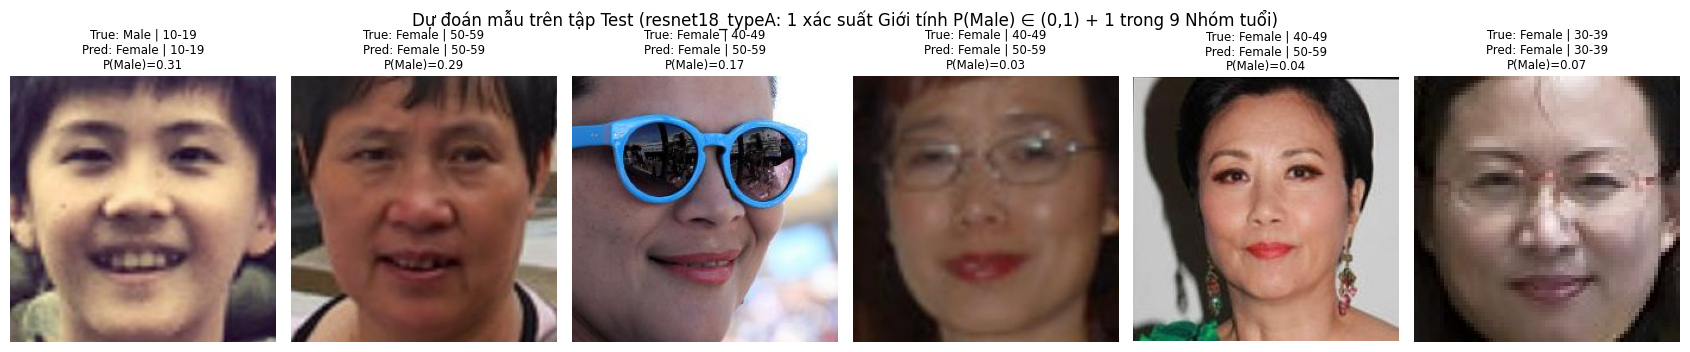

In [8]:
# [Cell 8] Phân tích kết quả theo từng Nhóm tuổi & Trực quan hóa dự đoán mẫu trên tập Test
test_meta = test_ds.df.copy()
test_meta["p_male_sigmoid"] = np.round(gender_prob_male, 4)
test_meta["pred_gender_idx"] = gender_pred
test_meta["true_age_grp_idx"] = age_grp_true
test_meta["pred_age_grp_idx"] = age_grp_pred
test_meta["pred_age_group"] = [AGE_GROUPS_9[i] for i in age_grp_pred]
test_meta["age_exact_correct"] = (age_grp_pred == age_grp_true).astype(int)
test_meta["age_adj_correct"] = (np.abs(age_grp_pred - age_grp_true) <= 1).astype(int)

print("=== ĐỘ CHÍNH XÁC THEO TỪNG NHÓM TUỔI (EXACT vs ADJACENT ±1 NHÓM) ===")
grp_report = test_meta.groupby("age_group")[["age_exact_correct", "age_adj_correct"]].agg(
    count=("age_exact_correct", "count"),
    exact_acc_pct=("age_exact_correct", lambda s: round(s.mean() * 100, 2)),
    adjacent_acc_pct=("age_adj_correct", lambda s: round(s.mean() * 100, 2)),
).reindex(AGE_GROUPS_9)
display(grp_report)

sample_rows = test_meta.sample(6, random_state=42)
fig, axes = plt.subplots(1, 6, figsize=(17, 3.8))
for ax, row in zip(axes, sample_rows.itertuples()):
    with Image.open(str(row.image_path).replace("\\", "/")) as im:
        ax.imshow(im.convert("RGB"))
    g_true = "Female" if row.gender == 0 else "Male"
    g_pred = "Female" if row.pred_gender_idx == 0 else "Male"
    ax.set_title(
        f"True: {g_true} | {row.age_group}\n"
        f"Pred: {g_pred} | {row.pred_age_group}\n"
        f"P(Male)={row.p_male_sigmoid:.2f}",
        fontsize=8.5,
    )
    ax.axis("off")
plt.suptitle(f"Dự đoán mẫu trên tập Test ({EXP_TAG}: 1 xác suất Giới tính P(Male) ∈ (0,1) + 1 trong 9 Nhóm tuổi)", fontsize=12)
plt.tight_layout(); plt.show()

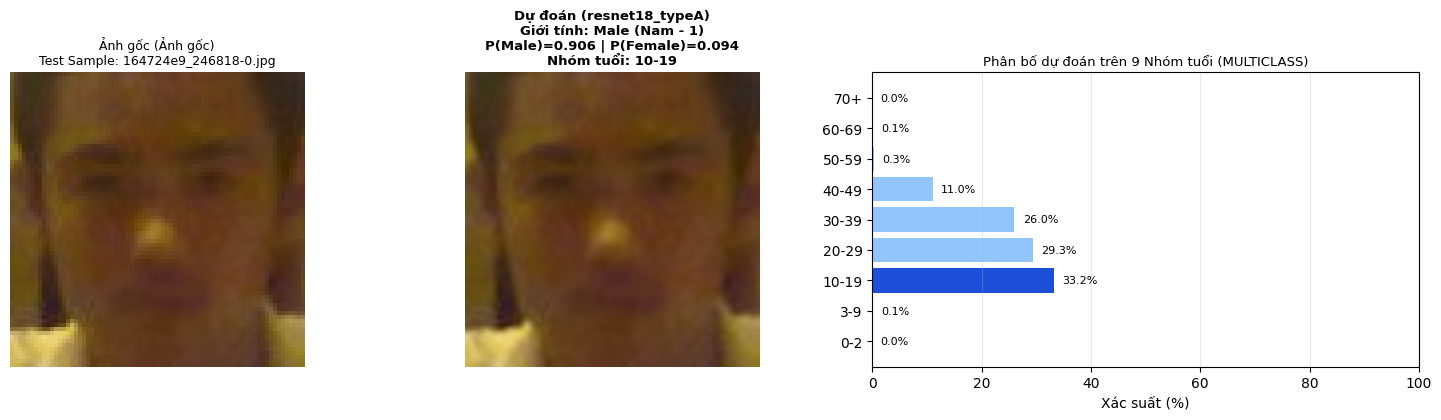

{
  "predicted_gender": "Male (Nam - 1)",
  "gender_sigmoid_prob_male": 0.9064,
  "gender_probabilities": {
    "Female (0)": 0.0936,
    "Male (1)": 0.9064
  },
  "predicted_age_group": "10-19",
  "age_group_probabilities": {
    "0-2": 0.0,
    "3-9": 0.001,
    "10-19": 0.332,
    "20-29": 0.293,
    "30-39": 0.26,
    "40-49": 0.1099,
    "50-59": 0.0031,
    "60-69": 0.001,
    "70+": 0.0
  }
}


In [9]:
# [Cell 9] Tải ảnh từ Internet (URL) hoặc tải file từ máy lên để Dự đoán Giới tính (1 xác suất) & Nhóm tuổi (9 nhóm)
import io, urllib.request
import cv2

def load_image_from_url_or_path(url="", local_path="", upload_on_colab=False):
    """Hỗ trợ 3 cách lấy ảnh:
    1. Dán link ảnh trên mạng vào `url` (http/https)
    2. Truyền đường dẫn ảnh trong máy vào `local_path`
    3. Đặt `upload_on_colab=True` để bấm nút chọn file trực tiếp trên Google Colab
    """
    if upload_on_colab and IN_COLAB:
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            fname = next(iter(uploaded.keys()))
            return Image.open(io.BytesIO(uploaded[fname])).convert("RGB"), f"Uploaded: {fname}"
    if url and url.strip():
        req = urllib.request.Request(url.strip(), headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=15) as resp:
            return Image.open(io.BytesIO(resp.read())).convert("RGB"), f"URL: {url.strip()[:50]}..."
    if local_path and os.path.exists(local_path):
        return Image.open(local_path).convert("RGB"), f"File: {os.path.basename(local_path)}"
    fallback_path = str(test_ds.df.iloc[0]["image_path"]).replace("\\", "/")
    return Image.open(fallback_path).convert("RGB"), f"Test Sample: {os.path.basename(fallback_path)}"

def detect_and_crop_face(pil_img, margin_ratio=0.25):
    """Tự động phát hiện khuôn mặt bằng Haar Cascade (hữu ích khi ảnh tải từ mạng có khung cảnh rộng)."""
    img_np = np.array(pil_img)
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    cascade_path = os.path.join(cv2.data.haarcascades, "haarcascade_frontalface_default.xml")
    face_cascade = cv2.CascadeClassifier(cascade_path)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(48, 48))
    if len(faces) == 0:
        return pil_img, None
    x, y, w, h = max(faces, key=lambda b: b[2] * b[3])
    H, W = img_np.shape[:2]
    mx, my = int(w * margin_ratio), int(h * margin_ratio)
    x1, y1 = max(0, x - mx), max(0, y - my)
    x2, y2 = min(W, x + w + mx), min(H, y + h + my)
    return pil_img.crop((x1, y1, x2, y2)), (x1, y1, x2, y2)

def predict_single_image(url="", local_path="", upload_on_colab=False, auto_crop_face=True):
    raw_img, src_label = load_image_from_url_or_path(url=url, local_path=local_path, upload_on_colab=upload_on_colab)
    face_img, bbox = detect_and_crop_face(raw_img) if auto_crop_face else (raw_img, None)

    model.eval()
    x_tensor = val_transform(face_img).unsqueeze(0).to(device)
    with torch.no_grad():
        g_prob_male_t, a_pred_grp_t, a_scores_t = model.predict_proba(x_tensor)

    p_male = float(g_prob_male_t.item())
    p_female = 1.0 - p_male
    pred_gender_str = "Male (Nam - 1)" if p_male >= 0.5 else "Female (Nữ - 0)"
    pred_age_idx = int(a_pred_grp_t.item())
    pred_age_group = AGE_GROUPS_9[pred_age_idx]
    scores_np = a_scores_t.squeeze(0).cpu().numpy()

    if AGE_MODE == "coral":
        p_gt = np.clip(scores_np, 0.0, 1.0)
        probs_9 = np.zeros(9, dtype=np.float32)
        probs_9[0] = 1.0 - p_gt[0]
        for k in range(1, 8):
            probs_9[k] = max(0.0, p_gt[k - 1] - p_gt[k])
        probs_9[8] = p_gt[7]
        if probs_9.sum() > 0:
            probs_9 = probs_9 / probs_9.sum()
    else:
        probs_9 = scores_np

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.4]})
    img_draw = np.array(raw_img).copy()
    if bbox is not None:
        cv2.rectangle(img_draw, (bbox[0], bbox[1]), (bbox[2], bbox[3]), (0, 255, 0), max(2, img_draw.shape[1] // 150))
    axes[0].imshow(img_draw)
    axes[0].set_title(f"Ảnh gốc ({'Đã cắt mặt' if bbox else 'Ảnh gốc'})\n{src_label}", fontsize=9)
    axes[0].axis("off")

    axes[1].imshow(face_img.resize((IMG_SIZE, IMG_SIZE)))
    axes[1].set_title(
        f"Dự đoán ({EXP_TAG})\n"
        f"Giới tính: {pred_gender_str}\n"
        f"P(Male)={p_male:.3f} | P(Female)={p_female:.3f}\n"
        f"Nhóm tuổi: {pred_age_group}",
        fontsize=9.5,
        fontweight="bold",
    )
    axes[1].axis("off")

    colors = ["#1d4ed8" if i == pred_age_idx else "#93c5fd" for i in range(9)]
    axes[2].barh(AGE_GROUPS_9, probs_9 * 100.0, color=colors)
    axes[2].set_xlim(0, 100)
    axes[2].set_xlabel("Xác suất (%)")
    axes[2].set_title(f"Phân bố dự đoán trên 9 Nhóm tuổi ({AGE_MODE.upper()})", fontsize=9.5)
    axes[2].grid(axis="x", alpha=0.3)
    for i, v in enumerate(probs_9 * 100.0):
        axes[2].text(min(v + 1.5, 92.0), i, f"{v:.1f}%", va="center", fontsize=8)

    plt.tight_layout()
    plt.show()

    return {
        "predicted_gender": pred_gender_str,
        "gender_sigmoid_prob_male": round(p_male, 4),
        "gender_probabilities": {"Female (0)": round(p_female, 4), "Male (1)": round(p_male, 4)},
        "predicted_age_group": pred_age_group,
        "age_group_probabilities": {AGE_GROUPS_9[i]: round(float(probs_9[i]), 4) for i in range(9)},
    }

# ================= HƯỚNG DẪN SỬ DỤNG =================
# 1. Dán link ảnh khuôn mặt bất kỳ trên mạng vào IMAGE_URL:
IMAGE_URL = ""  # Ví dụ: "https://..."
# 2. Hoặc điền đường dẫn file ảnh trong máy / Colab:
LOCAL_IMAGE_PATH = ""
# 3. Hoặc đổi UPLOAD_FROM_COMPUTER = True trên Colab để chọn file từ máy tính:
UPLOAD_FROM_COMPUTER = False

result = predict_single_image(
    url=IMAGE_URL,
    local_path=LOCAL_IMAGE_PATH,
    upload_on_colab=UPLOAD_FROM_COMPUTER,
    auto_crop_face=True,
)
print(json.dumps(result, indent=2, ensure_ascii=False))